# Faz 4b — Çalışma Noktası Kararsızlığının Doğrulanması

## Faz 4a'nın gösterdiği

`log_q99` stratejisinde zor saldırı türlerinde yakalama oranı:

| Cihaz | tohum 7 | tohum 42 |
|---|---|---|
| Ennio kapı zili | 0,09 | **100,00** |
| Philips bebek monitörü | **99,99** | 0,09 |
| Provision PT-838 | **100,00** | 0,10 |

Ara değer yok. Üç cihazda sonuç yalnızca rastgelelik tohumuna göre tamamen değişiyor.

## Bu notebook iki şeyi doğruluyor

**Bölüm A --- Hata dağılımlarının yapısı.** Eğitim gerektirmez; Faz 4a checkpoint'indeki
hatalar kullanılır. Hipotez: zor saldırıların yeniden yapılandırma hataları dar bir bantta
toplanmış ve bu bant iyi huylu trafiğin ağır kuyruğunun içine düşüyor. Doğruysa, eşiğin
bandın hangi tarafına düştüğü tespiti belirler ve ara değer oluşmaz.

**Bölüm B --- Kararsızlığın ölçülmesi.** On tohumla yeniden eğitim. Her cihaz için
"kaç koşuda doğru tarafa düştü" sayılır. Kararsızlık artık bir gözlem değil, ölçülmüş
bir büyüklük olur.

---

### Tanımlanacak metrik: çalışma noktası kararlılığı

Bir cihaz--saldırı--strateji üçlüsü için, $K$ bağımsız koşuda elde edilen yakalama
oranlarının dağılımı. Üç özet:

- **Ortalama yakalama** --- beklenen başarım
- **Kararlılık** $= \max(\bar{p}, 1-\bar{p})$ --- koşuların ne kadarı aynı tarafa düşüyor
  (1,0 tam kararlı, 0,5 tam yazı tura)
- **İkili olma oranı** --- sonuçların kaçta kaçı uçlarda (<0,05 veya >0,95)

Bu üçlü, tek bir koşudan bildirilen sonucun ne kadar güvenilir olduğunu söyler.

## 0. Ortam

In [1]:
import sys, os, glob, time, json, pickle, random, warnings
from collections import defaultdict

_PYLIBS = os.path.expanduser("~/work/pylibs")
if os.path.isdir(_PYLIBS) and _PYLIBS not in sys.path:
    sys.path.insert(0, _PYLIBS)
for v in ("OMP_NUM_THREADS","OPENBLAS_NUM_THREADS","MKL_NUM_THREADS"):
    os.environ[v] = "8"
os.environ["CUDA_CACHE_PATH"] = os.path.expanduser("~/work/.cuda_cache")
os.makedirs(os.environ["CUDA_CACHE_PATH"], exist_ok=True)

import ctypes
try:
    import nvidia
    libdirs = sorted(glob.glob(os.path.join(os.path.dirname(nvidia.__file__), "*", "lib")))
    os.environ["LD_LIBRARY_PATH"] = ":".join(libdirs) + ":" + os.environ.get("LD_LIBRARY_PATH","")
    n = 0
    for d in libdirs:
        for so in sorted(glob.glob(os.path.join(d, "*.so*"))):
            try: ctypes.CDLL(so, mode=ctypes.RTLD_GLOBAL); n += 1
            except OSError: pass
    print(f"{n} CUDA kutuphanesi on-yuklendi")
except ImportError:
    print("CPU")

import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt; import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")
matplotlib.rcParams["figure.dpi"] = 60
matplotlib.rcParams["savefig.dpi"] = 300
matplotlib.rcParams["savefig.bbox"] = "tight"
print("TF", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

31 CUDA kutuphanesi on-yuklendi


I0000 00:00:1791187222.191306   10131 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791187222.388816   10131 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791187223.041219   10131 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1791187223.444529   10131 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binar

TF 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
KOK  = os.path.expanduser("~/work/IoT_Botnet/veri/nbaiot")
F4A  = os.path.expanduser("~/work/IoT_Botnet/faz4a_ciktilar")
OUT  = os.path.expanduser("~/work/IoT_Botnet/faz4b_ciktilar")
for s in ("figures","tables"): os.makedirs(f"{OUT}/{s}", exist_ok=True)
CKPT = f"{OUT}/faz4b_checkpoint.pkl"

TOHUMLAR = [42, 7, 2024, 13, 101, 777, 5, 31415, 2718, 99]   # 10 kosu
EPOCHS, BATCH, PATIENCE, LR, KOD = 60, 256, 8, 1e-3, 16
KALIBRASYON, ESIK_DILIM = 0.60, 0.10
HEDEF_FPR = 0.01
SALDIRI_TEST = 30_000
ZOR = ["gafgyt:tcp", "gafgyt:udp"]
UC_ALT, UC_UST = 0.05, 0.95     # "ikili" sayilma esikleri

def set_seed(s):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
    os.environ["PYTHONHASHSEED"] = str(s)
def savefig(a):
    plt.savefig(f"{OUT}/figures/{a}.png"); plt.show()
print("Cikti:", OUT)

Cikti: /home/jovyan/work/IoT_Botnet/faz4b_ciktilar


In [3]:
def bilgi(y):
    p = os.path.relpath(y, KOK).split(os.sep)
    if len(p) == 2: return p[0], "benign", "benign"
    return p[0], p[1].replace("_attacks",""), os.path.splitext(p[-1])[0]

dosyalar = [f for f in sorted(glob.glob(f"{KOK}/**/*.csv", recursive=True))
            if "demonstrate" not in f]
t0 = time.time(); IYI, SALDIRI = {}, defaultdict(dict)
for f in dosyalar:
    c, a, t = bilgi(f)
    df = pd.read_csv(f, dtype="float32")
    if a == "benign": IYI[c] = df.to_numpy()
    else: SALDIRI[c][f"{a}:{t}"] = df.to_numpy()[:SALDIRI_TEST]

OZN = list(pd.read_csv(dosyalar[0], nrows=1).columns)
CIHAZLAR = sorted(IYI)
def bol(A):
    n=len(A); i1=int(KALIBRASYON*n); i2=int((KALIBRASYON+ESIK_DILIM)*n)
    return A[:i1], A[i1:i2], A[i2:]
BOLUM = {c: dict(zip(("kal","esik","test"), bol(IYI[c]))) for c in CIHAZLAR}
print(f"Yuklendi ({time.time()-t0:.0f}s) | {len(CIHAZLAR)} cihaz")

Yuklendi (30s) | 9 cihaz


# Bölüm A — Hata dağılımlarının yapısı

Faz 4a checkpoint'i kullanılıyor, eğitim yok.

Her cihaz için üç dağılım karşılaştırılıyor: iyi huylu test, kolay saldırı türleri,
zor saldırı türleri. Hipotez doğruysa zor türler **dar bir tepe** oluşturmalı ve bu tepe
iyi huylu dağılımın kuyruğuyla çakışmalı.

In [4]:
with open(f"{F4A}/faz4a_checkpoint.pkl", "rb") as f:
    H4A = pickle.load(f)
print(f"Faz 4a kaydi: {len(H4A)} anahtar")

satir = []
for c in CIHAZLAR:
    h = H4A.get(("D-D", c, 42))
    if h is None: continue
    iyi = h["test"]
    zor = [h["sal"][t] for t in ZOR if t in h["sal"]]
    kolay = [h["sal"][t] for t in h["sal"] if t not in ZOR]
    if not zor: continue
    Z = np.concatenate(zor); K = np.concatenate(kolay) if kolay else np.array([])
    lz = np.log10(Z + 1e-12)
    satir.append({
        "cihaz": c,
        "iyi_medyan": float(np.median(iyi)),
        "iyi_q99": float(np.quantile(iyi, 0.99)),
        "iyi_q999": float(np.quantile(iyi, 0.999)),
        "zor_medyan": float(np.median(Z)),
        # bandin darligi: log10 uzayinda q95-q05 araligi
        "zor_bant_genisligi_log10": float(np.quantile(lz,0.95) - np.quantile(lz,0.05)),
        "iyi_bant_genisligi_log10": float(np.quantile(np.log10(iyi+1e-12),0.95)
                                          - np.quantile(np.log10(iyi+1e-12),0.05)),
        "kolay_medyan": float(np.median(K)) if len(K) else np.nan,
        # zor saldiri iyi huylu dagilimin hangi yuzdeliginde?
        "zor_iyi_yuzdeligi": float((iyi < np.median(Z)).mean()),
    })
yapi = pd.DataFrame(satir)
yapi.to_csv(f"{OUT}/tables/f4b_tablo1_dagilim_yapisi.csv", index=False)
g = yapi.copy(); g["cihaz"] = [c[:28] for c in g.cihaz]
print(g[["cihaz","zor_bant_genisligi_log10","iyi_bant_genisligi_log10",
         "zor_iyi_yuzdeligi"]].round(3).to_string(index=False))
print("\nzor_bant_genisligi: zor saldirilarin hata dagiliminin log10 uzayinda genisligi")
print("                   (kucuk = dar tepe, bicak sirti riski yuksek)")
print("zor_iyi_yuzdeligi : zor saldirinin medyani, iyi huylu dagilimin kacinci yuzdeliginde")
print("                   (0,99'a yakin = esik tam oraya dusuyor = kararsiz)")

Faz 4a kaydi: 36 anahtar
                       cihaz  zor_bant_genisligi_log10  iyi_bant_genisligi_log10  zor_iyi_yuzdeligi
            Danmini_Doorbell                       0.0                     1.966              0.997
           Ecobee_Thermostat                       0.0                     1.930              0.869
              Ennio_Doorbell                       0.0                     1.906              0.987
Philips_B120N10_Baby_Monitor                       0.0                     1.985              0.966
Provision_PT_737E_Security_C                       0.0                     1.733              0.988
Provision_PT_838_Security_Ca                       0.0                     1.475              0.986
   Samsung_SNH_1011_N_Webcam                       0.0                     1.923              0.968
SimpleHome_XCS7_1002_WHT_Sec                       0.0                     1.931              0.983
SimpleHome_XCS7_1003_WHT_Sec                       0.0                     

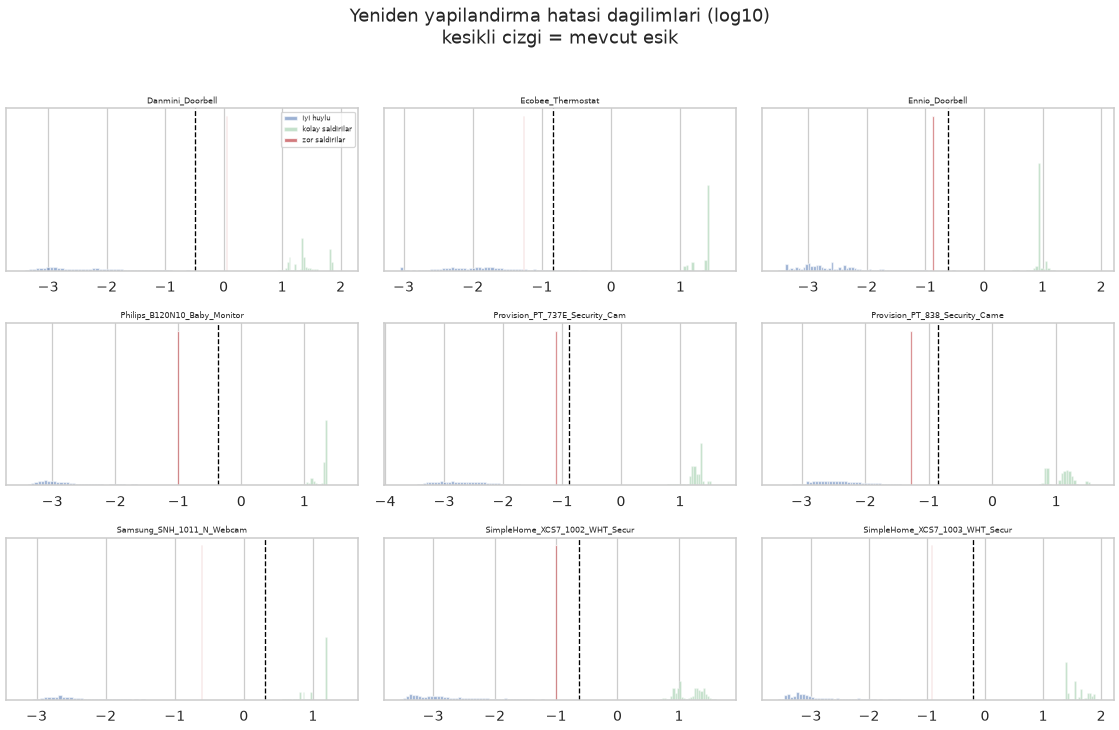

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(19, 12))
for ax, c in zip(axes.ravel(), CIHAZLAR):
    h = H4A.get(("D-D", c, 42))
    if h is None: continue
    iyi = np.log10(h["test"] + 1e-12)
    ax.hist(iyi, bins=80, density=True, alpha=0.55,
            color="#4c72b0", label="iyi huylu")
    kolay = [h["sal"][t] for t in h["sal"] if t not in ZOR]
    if kolay:
        ax.hist(np.log10(np.concatenate(kolay)+1e-12), bins=80, density=True,
                alpha=0.35, color="#55a868", label="kolay saldirilar")
    zor = [h["sal"][t] for t in ZOR if t in h["sal"]]
    if zor:
        ax.hist(np.log10(np.concatenate(zor)+1e-12), bins=80, density=True,
                alpha=0.75, color="#c44e52", label="zor saldirilar")
    ax.axvline(np.log10(np.quantile(h["esik"], 0.99)+1e-12),
               color="black", ls="--", lw=1.6)
    ax.set_title(c[:30], fontsize=10); ax.set_yticks([])
axes[0][0].legend(fontsize=8)
plt.suptitle("Yeniden yapilandirma hatasi dagilimlari (log10)\n"
             "kesikli cizgi = mevcut esik", y=1.02)
plt.tight_layout(); savefig("f4b_fig01_dagilimlar")

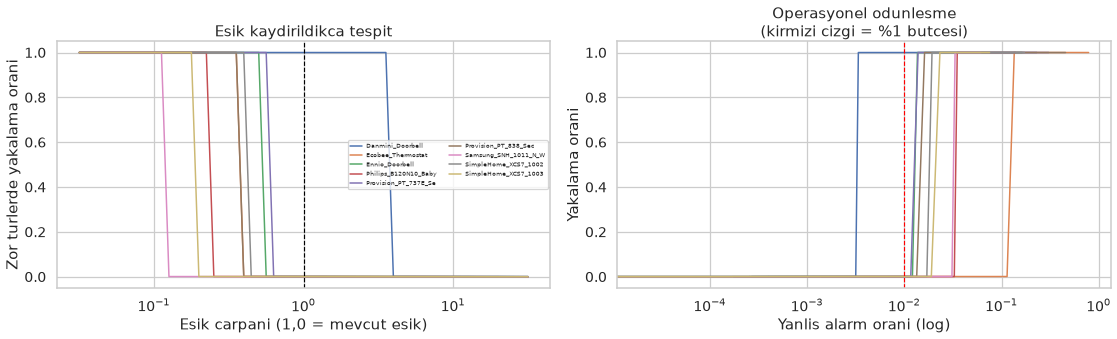

Zor turlerde %90 yakalama icin gereken yanlis alarm orani:

                       cihaz  FPR_TPR90  FPR_TPR10  FPR_bedeli
            Danmini_Doorbell     0.0034     0.0032      1.0638
           Ecobee_Thermostat     0.1350     0.1139      1.1853
              Ennio_Doorbell     0.0136     0.0121      1.1268
Philips_B120N10_Baby_Monitor     0.0350     0.0326      1.0717
Provision_PT_737E_Security_C     0.0138     0.0116      1.1889
Provision_PT_838_Security_Ca     0.0161     0.0134      1.2045
   Samsung_SNH_1011_N_Webcam     0.0332     0.0309      1.0766
SimpleHome_XCS7_1002_WHT_Sec     0.0192     0.0170      1.1303
SimpleHome_XCS7_1003_WHT_Sec     0.0232     0.0189      1.2252


In [6]:
# ---- Bicak sirti: esik kucuk kaydirildiginda TPR ne oluyor? -------------
carpanlar = np.logspace(-1.5, 1.5, 61)     # esigin 0.03 - 31 kati
satir = []
for c in CIHAZLAR:
    h = H4A.get(("D-D", c, 42))
    if h is None: continue
    zor = [h["sal"][t] for t in ZOR if t in h["sal"]]
    if not zor: continue
    Z = np.concatenate(zor); taban = float(np.quantile(h["esik"], 0.99))
    for k in carpanlar:
        e = taban * k
        satir.append({"cihaz": c, "carpan": float(k),
                      "TPR_zor": float((Z > e).mean()),
                      "FPR": float((h["test"] > e).mean())})
egri = pd.DataFrame(satir)
egri.to_csv(f"{OUT}/tables/f4b_tablo2_esik_duyarliligi.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(19, 6))
for c in CIHAZLAR:
    g = egri[egri.cihaz == c]
    ax[0].plot(g.carpan, g.TPR_zor, lw=1.8, label=c[:20])
    ax[1].plot(g.FPR, g.TPR_zor, lw=1.8)
ax[0].set_xscale("log"); ax[0].axvline(1.0, color="black", ls="--", lw=1.4)
ax[0].set_xlabel("Esik carpani (1,0 = mevcut esik)")
ax[0].set_ylabel("Zor turlerde yakalama orani")
ax[0].set_title("Esik kaydirildikca tespit")
ax[0].legend(fontsize=7, ncol=2)
ax[1].set_xscale("log"); ax[1].axvline(0.01, color="red", ls="--", lw=1.4)
ax[1].set_xlabel("Yanlis alarm orani (log)"); ax[1].set_ylabel("Yakalama orani")
ax[1].set_title("Operasyonel odunlesme\n(kirmizi cizgi = %1 butcesi)")
plt.tight_layout(); savefig("f4b_fig02_bicak_sirti")

# gecis genisligi: TPR 0.1'den 0.9'a cikarken FPR kac kat artiyor?
satir = []
for c in CIHAZLAR:
    g = egri[egri.cihaz == c].sort_values("carpan")
    try:
        f_lo = g[g.TPR_zor >= 0.9].FPR.min()
        f_hi = g[g.TPR_zor <= 0.1].FPR.max()
        satir.append({"cihaz": c, "FPR_TPR90": f_lo, "FPR_TPR10": f_hi,
                      "FPR_bedeli": f_lo / (f_hi + 1e-12)})
    except Exception:
        pass
gec = pd.DataFrame(satir)
gec.to_csv(f"{OUT}/tables/f4b_tablo3_gecis.csv", index=False)
gec["cihaz"] = [c[:28] for c in gec.cihaz]
print("Zor turlerde %90 yakalama icin gereken yanlis alarm orani:\n")
print(gec.round(4).to_string(index=False))

# Bölüm B — Kararsızlığın ölçülmesi (10 tohum)

Her cihaz için model 10 farklı rastgelelik tohumuyla yeniden eğitiliyor. Eşik stratejisi
sabit tutuluyor, böylece değişkenliğin tek kaynağı eğitimin rastgeleliği oluyor.

Üç strateji karşılaştırılıyor: mevcut (`q99_esik`), Faz 4a'da en iyi gerçekçi çıkan
(`log_q99`) ve budanmış yüzdelik (`q99_budanmis`).

Yaklaşık 90 eğitim, GPU'da 45-60 dakika. Her tohum sonunda diske kayıt.

In [7]:
def ae(boyut, tohum):
    set_seed(tohum)
    i = layers.Input(shape=(boyut,))
    x = layers.Dense(64, activation="relu")(i)
    x = layers.Dense(32, activation="relu")(x)
    k = layers.Dense(KOD, activation="relu")(x)
    x = layers.Dense(32, activation="relu")(k)
    x = layers.Dense(64, activation="relu")(x)
    m = models.Model(i, layers.Dense(boyut, activation="linear")(x))
    m.compile(optimizer=tf.keras.optimizers.Adam(LR), loss="mse")
    return m

def egit(kal, tohum):
    mu, sd = kal.mean(0), kal.std(0) + 1e-8
    X = np.clip((kal-mu)/sd, -20, 20).astype("float32")
    nv = max(1, int(0.1*len(X)))
    m = ae(X.shape[1], tohum)
    m.fit(X[:-nv], X[:-nv], validation_data=(X[-nv:], X[-nv:]),
          epochs=EPOCHS, batch_size=BATCH, verbose=0,
          callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                             restore_best_weights=True)])
    return m, mu, sd

def hata(m, mu, sd, A):
    X = np.clip((A-mu)/sd, -20, 20).astype("float32")
    R = m.predict(X, batch_size=4096, verbose=0)
    return np.mean((X-R)**2, axis=1).astype("float32")

def mad(x):
    med = np.median(x); return float(np.median(np.abs(x-med)))

def esik_hesapla(e):
    kes = np.quantile(e, 0.99); bud = e[e <= kes]
    le = np.log10(e + 1e-12)
    return {"q99_esik": float(np.quantile(e, 0.99)),
            "q99_budanmis": float(np.quantile(bud, 0.99)),
            "log_q99": float(10 ** (le.mean() + 2.33*le.std()))}

In [8]:
if os.path.exists(CKPT):
    with open(CKPT,"rb") as f: D = pickle.load(f)
    print(f"Onceki kayit: {len(D['kosular'])} satir")
else:
    D = {"kosular": []}
    print("Yeni kosu")

tamam = {(r["cihaz"], r["tohum"], r["strateji"]) for r in D["kosular"]}
t0 = time.time()

for ti, tohum in enumerate(TOHUMLAR, 1):
    print(f"\n--- tohum {tohum}  ({ti}/{len(TOHUMLAR)}) ---")
    for c in CIHAZLAR:
        if all((c, tohum, s) in tamam for s in ("q99_esik","q99_budanmis","log_q99")):
            continue
        m, mu, sd = egit(BOLUM[c]["kal"], tohum)
        h_esik = hata(m, mu, sd, BOLUM[c]["esik"])
        h_test = hata(m, mu, sd, BOLUM[c]["test"])
        h_sal  = {t: hata(m, mu, sd, A) for t, A in SALDIRI[c].items()}
        del m; tf.keras.backend.clear_session()

        tum = np.concatenate(list(h_sal.values()))
        zorl = [h_sal[t] for t in ZOR if t in h_sal]
        Z = np.concatenate(zorl) if zorl else None

        for sad, e in esik_hesapla(h_esik).items():
            D["kosular"].append({
                "cihaz": c, "tohum": tohum, "strateji": sad, "esik": e,
                "TPR": float((tum > e).mean()),
                "TPR_zor": float((Z > e).mean()) if Z is not None else np.nan,
                "FPR": float((h_test > e).mean()),
            })
        print(f"  {c[:34]:<36} bitti")
    with open(CKPT,"wb") as f: pickle.dump(D, f)

print(f"\nSure: {(time.time()-t0)/60:.1f} dk | {len(D['kosular'])} satir")
kos = pd.DataFrame(D["kosular"])
kos.to_csv(f"{OUT}/tables/f4b_tablo4_cok_tohum_ham.csv", index=False)

Yeni kosu

--- tohum 42  (1/10) ---


W0000 00:00:1791187255.953177   10131 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1791187256.038123   10131 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 94890 MB memory:  -> device: 0, name: NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition, pci bus id: 0000:02:00.0, compute capability: 12.0a
I0000 00:00:1791187257.868073   10331 service.cc:153] XLA service 0x703ac8033ab0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791187257.868092   10331 service.cc:161]   StreamExecutor [0]: NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition, Compute Capability 12.0a (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1791187257.893336   10331 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var

  Danmini_Doorbell                     bitti


I0000 00:00:1791187283.350311   10332 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_28939__.9
I0000 00:00:1791187284.328918   10333 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_28939__.9
I0000 00:00:1791187284.365982   10333 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1791187284.731150   10333 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1791187285.376256   10333 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a goo

  Ecobee_Thermostat                    bitti


...

  Samsung_SNH_1011_N_Webcam            bitti


I0000 00:00:1791188849.898824   10333 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2845453__.9
I0000 00:00:1791188851.025712   10333 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2845453__.9


  SimpleHome_XCS7_1002_WHT_Security_   bitti


I0000 00:00:1791188867.158964   10329 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2871454__.9
I0000 00:00:1791188868.123077   10334 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2871454__.9


  SimpleHome_XCS7_1003_WHT_Security_   bitti

Sure: 27.0 dk | 270 satir


In [9]:
# ---- Kararlilik metrikleri ---------------------------------------------
kos = pd.DataFrame(D["kosular"])

def kararlilik(g):
    v = g.TPR_zor.dropna().to_numpy()
    if len(v) == 0: return pd.Series(dtype=float)
    ust = (v > UC_UST).mean(); alt = (v < UC_ALT).mean()
    return pd.Series({
        "n_kosu": len(v),
        "TPR_ort": v.mean(),
        "TPR_std": v.std(),
        "TPR_min": v.min(),
        "TPR_max": v.max(),
        "ikili_oran": ust + alt,
        "ustte_oran": ust,
        "kararlilik": max(ust + (1-ust-alt)/2, alt + (1-ust-alt)/2),
    })

kar = kos.groupby(["strateji","cihaz"]).apply(kararlilik).reset_index()
kar.to_csv(f"{OUT}/tables/f4b_tablo5_kararlilik.csv", index=False)

for s in ["q99_esik","q99_budanmis","log_q99"]:
    a = kar[kar.strateji == s].copy()
    if a.empty: continue
    a["cihaz"] = [c[:28] for c in a.cihaz]
    print(f"\n=== {s} ===")
    print(a[["cihaz","n_kosu","TPR_ort","TPR_std","TPR_min","TPR_max",
             "ustte_oran","kararlilik"]].round(3).to_string(index=False))


=== q99_esik ===
                       cihaz  n_kosu  TPR_ort  TPR_std  TPR_min  TPR_max  ustte_oran  kararlilik
            Danmini_Doorbell    10.0    1.000      0.0    1.000    1.000         1.0         1.0
           Ecobee_Thermostat    10.0    0.001      0.0    0.001    0.001         0.0         1.0
              Ennio_Doorbell    10.0    0.001      0.0    0.001    0.001         0.0         1.0
Philips_B120N10_Baby_Monitor    10.0    0.000      0.0    0.000    0.000         0.0         1.0
Provision_PT_737E_Security_C    10.0    0.101      0.3    0.001    1.000         0.1         0.9
Provision_PT_838_Security_Ca    10.0    0.101      0.3    0.001    1.000         0.1         0.9
   Samsung_SNH_1011_N_Webcam    10.0    0.000      0.0    0.000    0.000         0.0         1.0
SimpleHome_XCS7_1002_WHT_Sec    10.0    0.001      0.0    0.001    0.001         0.0         1.0
SimpleHome_XCS7_1003_WHT_Sec    10.0    0.001      0.0    0.001    0.001         0.0         1.0

=== q99_bud

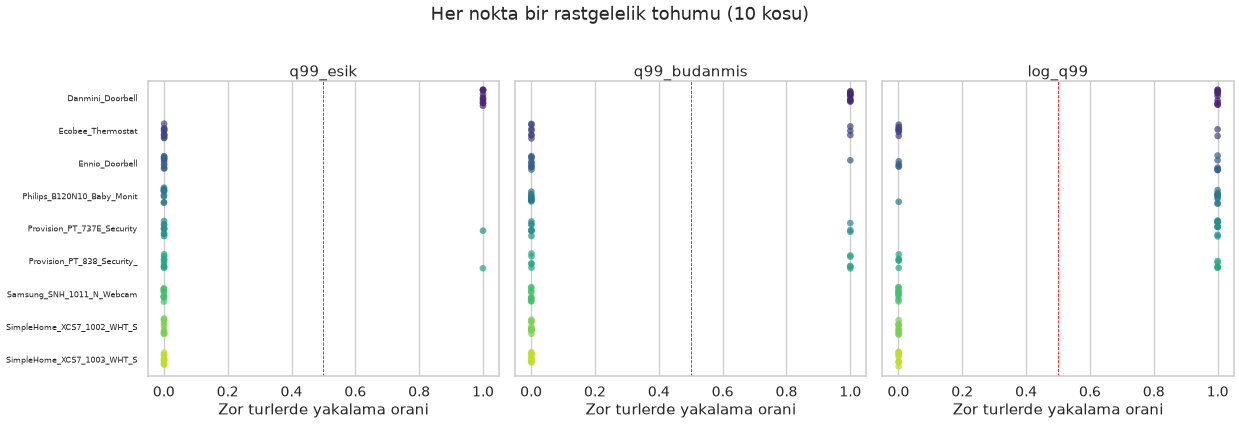

In [10]:
# ---- Sekil: her kosunun sonucu ------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(21, 7), sharey=True)
for ax, s in zip(axes, ["q99_esik","q99_budanmis","log_q99"]):
    a = kos[kos.strateji == s]
    if a.empty: continue
    sns.stripplot(data=a, y="cihaz", x="TPR_zor", ax=ax, size=8, alpha=0.7,
                  hue="cihaz", palette="viridis", legend=False, jitter=0.25,
                  order=CIHAZLAR)
    ax.set_title(s); ax.set_xlabel("Zor turlerde yakalama orani"); ax.set_ylabel("")
    ax.set_xlim(-0.05, 1.05)
    ax.axvline(0.5, color="red", ls="--", lw=1)
axes[0].set_yticklabels([c[:26] for c in CIHAZLAR], fontsize=9)
plt.suptitle(f"Her nokta bir rastgelelik tohumu ({len(TOHUMLAR)} kosu)", y=1.02)
plt.tight_layout(); savefig("f4b_fig03_kosu_dagilimi")

Tum kosular (270 adet):
  uclarda (<0.05 veya >0.95) : 100.0%
  ara degerde                        : 0.0%


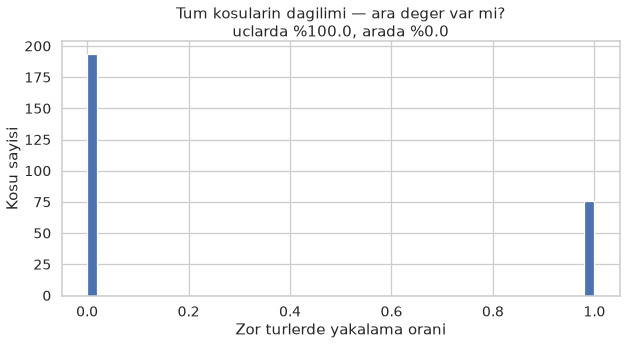


>> IKILI DAVRANIS DOGRULANDI. Sonuc esigin bandin hangi tarafina
   dustugune bagli; ara deger olusmuyor.


In [11]:
# ---- Ikili davranisin dogrulanmasi --------------------------------------
tum = kos.TPR_zor.dropna()
ikili = ((tum < UC_ALT) | (tum > UC_UST)).mean()
ara = ((tum >= UC_ALT) & (tum <= UC_UST)).mean()
print(f"Tum kosular ({len(tum)} adet):")
print(f"  uclarda (<{UC_ALT} veya >{UC_UST}) : {100*ikili:.1f}%")
print(f"  ara degerde                        : {100*ara:.1f}%")

plt.figure(figsize=(12, 5.5))
plt.hist(tum, bins=50, color="#4c72b0", edgecolor="white")
plt.xlabel("Zor turlerde yakalama orani"); plt.ylabel("Kosu sayisi")
plt.title(f"Tum kosularin dagilimi — ara deger var mi?\n"
          f"uclarda %{100*ikili:.1f}, arada %{100*ara:.1f}")
savefig("f4b_fig04_ikili_dagilim")

if ikili > 0.9:
    print("\n>> IKILI DAVRANIS DOGRULANDI. Sonuc esigin bandin hangi tarafina")
    print("   dustugune bagli; ara deger olusmuyor.")
elif ikili > 0.7:
    print("\n>> Agirlikli olarak ikili, ama ara degerler de var.")
else:
    print("\n>> Ikili davranis dogrulanmadi; dagilim surekli.")

In [12]:
# ---- Tek kosudan rapor etmenin riski ------------------------------------
risk = []
for s in kar.strateji.unique():
    a = kar[kar.strateji == s]
    kararsiz = a[(a.ustte_oran > 0.1) & (a.ustte_oran < 0.9)]
    risk.append({
        "strateji": s,
        "ortalama_kararlilik": round(float(a.kararlilik.mean()), 3),
        "kararsiz_cihaz": len(kararsiz),
        "toplam_cihaz": len(a),
        "ortalama_TPR": round(float(a.TPR_ort.mean()), 4),
        "TPR_std_ort": round(float(a.TPR_std.mean()), 4),
    })
rdf = pd.DataFrame(risk)
rdf.to_csv(f"{OUT}/tables/f4b_tablo6_risk.csv", index=False)
print(rdf.to_string(index=False))
print("\nkararsiz_cihaz: kosularin %10-90'inda bir tarafa dusen cihaz sayisi.")
print("Bu cihazlarda tek kosudan bildirilen sonuc yazı turadan farksizdir.")

    strateji  ortalama_kararlilik  kararsiz_cihaz  toplam_cihaz  ortalama_TPR  TPR_std_ort
     log_q99                0.867               3             9        0.4670       0.1876
q99_budanmis                0.867               3             9        0.2450       0.1906
    q99_esik                0.978               0             9        0.1339       0.0666

kararsiz_cihaz: kosularin %10-90'inda bir tarafa dusen cihaz sayisi.
Bu cihazlarda tek kosudan bildirilen sonuc yazı turadan farksizdir.


## Özet

In [13]:
ozet = {
    "bolum_A": {
        "zor_bant_genisligi_log10_ort": round(float(yapi.zor_bant_genisligi_log10.mean()), 3),
        "iyi_bant_genisligi_log10_ort": round(float(yapi.iyi_bant_genisligi_log10.mean()), 3),
        "zor_saldirinin_iyi_huylu_yuzdeligi_ort": round(float(yapi.zor_iyi_yuzdeligi.mean()), 4),
        "TPR90_icin_gereken_FPR_ort": round(float(gec.FPR_TPR90.mean()), 4),
    },
    "bolum_B": {
        "tohum_sayisi": len(TOHUMLAR),
        "uclarda_kalma_orani": round(float(ikili), 3),
        "strateji_bazli_risk": rdf.to_dict("records"),
    },
}
with open(f"{OUT}/tables/f4b_ozet.json","w") as fh:
    json.dump(ozet, fh, indent=2, ensure_ascii=False, default=str)
print(json.dumps(ozet, indent=2, ensure_ascii=False, default=str))

import shutil
ars = shutil.make_archive(os.path.expanduser("~/work/IoT_Botnet/faz4b_ciktilar"),
                          "zip", OUT)
print("\nArsiv:", ars, f"({os.path.getsize(ars)/1e6:.1f} MB)")

{
  "bolum_A": {
    "zor_bant_genisligi_log10_ort": 0.0,
    "iyi_bant_genisligi_log10_ort": 1.868,
    "zor_saldirinin_iyi_huylu_yuzdeligi_ort": 0.969,
    "TPR90_icin_gereken_FPR_ort": 0.0325
  },
  "bolum_B": {
    "tohum_sayisi": 10,
    "uclarda_kalma_orani": 1.0,
    "strateji_bazli_risk": [
      {
        "strateji": "log_q99",
        "ortalama_kararlilik": 0.867,
        "kararsiz_cihaz": 3,
        "toplam_cihaz": 9,
        "ortalama_TPR": 0.467,
        "TPR_std_ort": 0.1876
      },
      {
        "strateji": "q99_budanmis",
        "ortalama_kararlilik": 0.867,
        "kararsiz_cihaz": 3,
        "toplam_cihaz": 9,
        "ortalama_TPR": 0.245,
        "TPR_std_ort": 0.1906
      },
      {
        "strateji": "q99_esik",
        "ortalama_kararlilik": 0.978,
        "kararsiz_cihaz": 0,
        "toplam_cihaz": 9,
        "ortalama_TPR": 0.1339,
        "TPR_std_ort": 0.0666
      }
    ]
  }
}

Arsiv: /home/jovyan/work/IoT_Botnet/faz4b_ciktilar.zip (1.0 MB)


---

## Koşu sonrası kontrol listesi

1. **Uçlarda kalma oranı %90'ın üzerinde mi?** İkili davranış doğrulanmış olur.
2. **Kaç cihaz kararsız?** (koşuların %10--90'ında bir tarafa düşen) Bu sayı, tek koşuluk
   raporlamanın ne kadar güvenilmez olduğunu doğrudan gösterir.
3. **Zor saldırının iyi huylu yüzdeliği 0,99 civarında mı?** Eşiğin tam o noktaya düşmesi
   kararsızlığın kaynağıdır.
4. **%90 yakalama için gereken yanlış alarm oranı kaç?** Kullanılabilir çalışma noktası
   olup olmadığını bu sayı söyler.
5. **Hangi strateji daha kararlı?** Ortalama başarımdan önce kararlılığa bakılmalı.